In [7]:
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path
from numpy import sort as sort
import json
import random

PROJECT_ROOT=Path.cwd().parent
DATA_DIR=PROJECT_ROOT / "datasets" / "EuroSAT"
RESULT_DIR=PROJECT_ROOT / 'results'

In [8]:
train_df=pd.read_csv(DATA_DIR / "train.csv")
test_df=pd.read_csv(DATA_DIR / 'test.csv')
print(f"Total training images: {len(train_df)}")

with open(DATA_DIR / "label_map.json") as f:
    label_map = json.load(f)
class_names = [name for name, label_id in sorted(label_map.items(), key=lambda item: item[1])]

Total training images: 18900


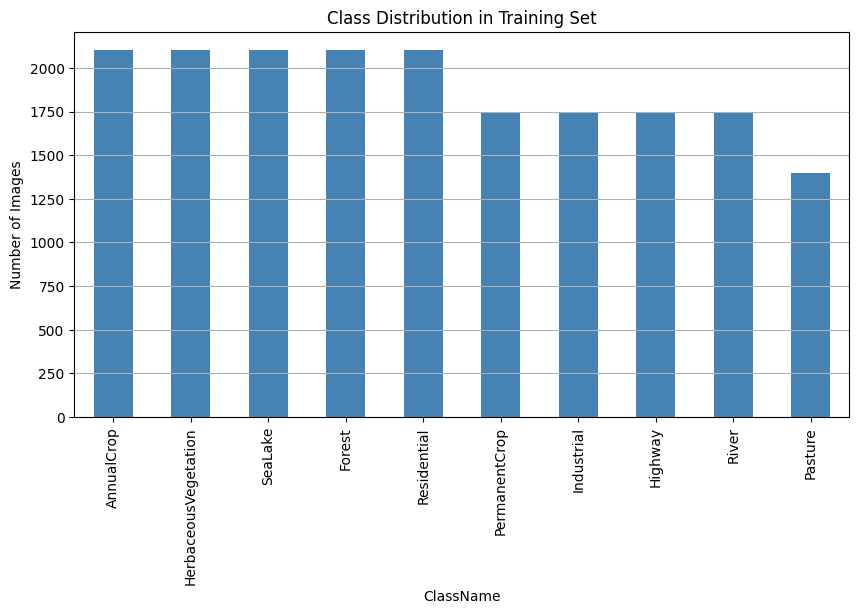

In [9]:
plt.figure(figsize=(10, 5))
train_df['ClassName'].value_counts().plot(kind='bar', color='steelblue')
plt.title("Class Distribution in Training Set")
plt.ylabel("Number of Images")
plt.grid(axis='y')
plt.show()

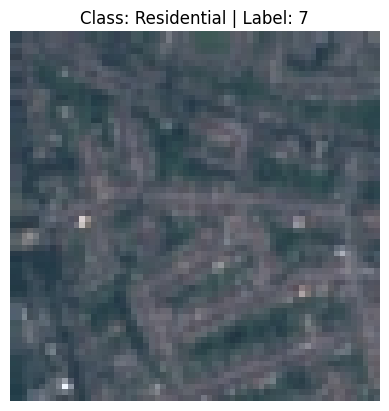

(64, 64)

In [10]:
random_idx = random.randint(0, len(train_df)-1)
sample = train_df.iloc[random_idx]

img_path = DATA_DIR / sample['Filename']
img = Image.open(img_path)

plt.imshow(img)
plt.title(f"Class: {sample['ClassName']} | Label: {sample['Label']}")
plt.axis('off')
plt.show()

img.size

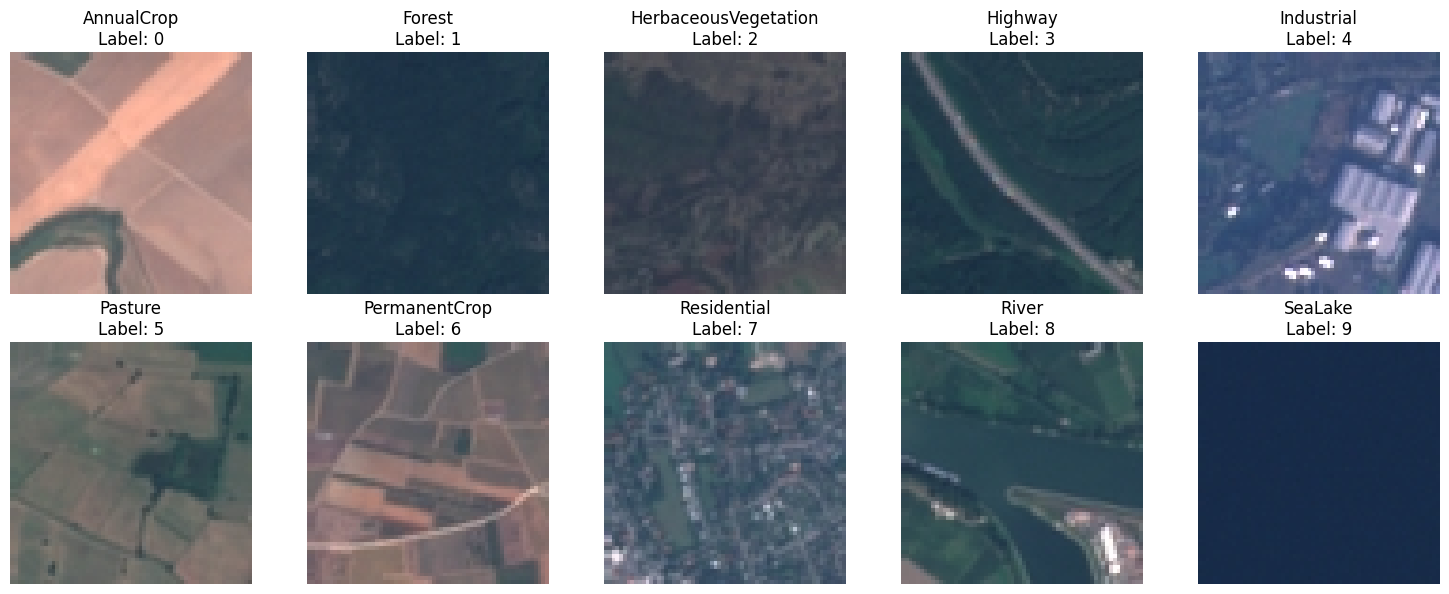

In [11]:
fig, axs = plt.subplots(2, 5, figsize=(15, 6))
unique_classes =sort(train_df['ClassName'].unique())

for ax, cls_name in zip(axs.ravel(), unique_classes):
    class_subset = train_df[train_df['ClassName'] == cls_name]
    sample = class_subset.sample(1).iloc[0]
    
    img_path = DATA_DIR / sample['Filename']
    img = Image.open(img_path)
    
    ax.imshow(img)
    ax.set_title(f"{cls_name}\nLabel: {sample['Label']}")
    ax.axis('off')

plt.tight_layout()
plt.show()

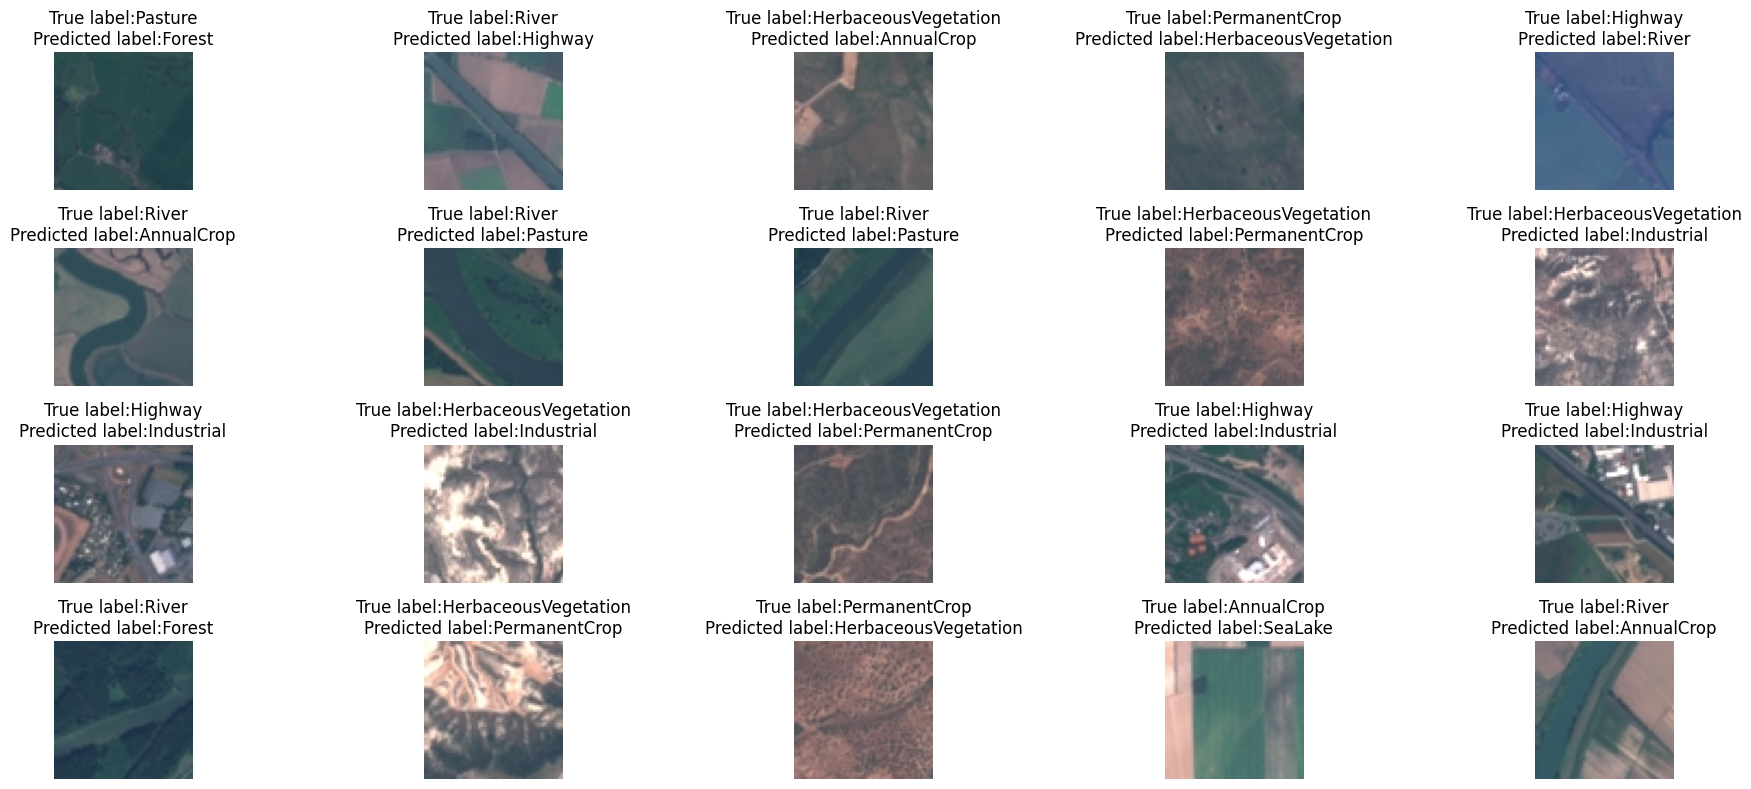

In [22]:
sample_id=[]
misclassified_pred_labels=[]
with open(RESULT_DIR / 'misclassified.json') as f:
    misclassified = json.load(f)
for sample in misclassified:
    sample_id.append(sample['sample_idx'])
samples=test_df.iloc[sample_id]
misclassified_true_labels=samples['ClassName']

for misses in misclassified:
    misclassified_pred_labels.append(class_names[misses['pred']])

fig, axs=plt.subplots(nrows=4, ncols=5, figsize=(20,8))
for ax, image, pred, true in zip(axs.ravel(), samples['Filename'], misclassified_pred_labels, misclassified_true_labels):
    full_img_path = DATA_DIR / Path(image)
    image = Image.open(full_img_path).convert("RGB")
    ax.imshow(image)
    ax.set_title(f'True label:{true}\nPredicted label:{pred}')
    ax.axis('off')

plt.tight_layout()
plt.show()